In [60]:
%pip install scikit-learn scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USUARIO\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [61]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USUARIO\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.makedirs("outputs", exist_ok=True)
import os
os.makedirs("outputs", exist_ok=True)
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

df = pd.read_csv("Fatal_Road_Traffic.csv")

In [63]:
print(df.shape)
print(df.columns.tolist())

(702540, 1)
['LLAVE;AÑO;FECHA_INCIDENTE;HORA_INCIDENTE;CLASE_INCIDENTE;GRAVEDAD_INCIDENTE;DIRECCION_INTERPOLADA;Latitud;Longitud;Codigo Comuna Planeacion;Comuna Planeacion;Codigo Barrio Planeacion;Barrio Planeacion']


#  1. Calidad de datos 

In [64]:
df.head(3)
df.info()
df = pd.read_csv("Fatal_Road_Traffic.csv", sep=";", decimal=",", na_values=["N/D", "Sin inf"])
 

<class 'pandas.DataFrame'>
MultiIndex: 702540 entries, ('1;2008;01/ene/2008;00:10:00;Choque;SOLO DAÑOS;Carrera 40 Con Calle 64;6', '25614811;-75') to ('702540;2025;31/ago/2025;23:30:00;Choque;HERIDO;Calle 95 Con Carrera 70;6', '29030491;-75')
Data columns (total 1 columns):
 #   Column                                                                                                                                                                                                    Non-Null Count   Dtype
---  ------                                                                                                                                                                                                    --------------   -----
 0   LLAVE;AÑO;FECHA_INCIDENTE;HORA_INCIDENTE;CLASE_INCIDENTE;GRAVEDAD_INCIDENTE;DIRECCION_INTERPOLADA;Latitud;Longitud;Codigo Comuna Planeacion;Comuna Planeacion;Codigo Barrio Planeacion;Barrio Planeacion  657625 non-null  str  
dtypes: str(1)
memory usage: 92.8 M

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_8764\3935662256.py:3: DtypeWarning: Columns (7: Latitud, 8: Longitud) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Fatal_Road_Traffic.csv", sep=";", decimal=",", na_values=["N/D", "Sin inf"])


In [65]:
meses = {"ene": "01", "feb": "02", "mar": "03", "abr": "04", "may": "05", "jun": "06",
         "jul": "07", "ago": "08", "sep": "09", "oct": "10", "nov": "11", "dic": "12"}
fecha_txt = df["FECHA_INCIDENTE"].astype(str).str.strip().str.lower()
for es, num in meses.items():
    fecha_txt = fecha_txt.str.replace("/" + es + "/", "/" + num + "/", regex=False)
df["fecha"] = pd.to_datetime(fecha_txt, format="%d/%m/%Y", errors="coerce")
print("Fechas que no se pudieron leer:", df["fecha"].isna().sum())   # debe ser 0
df["hora"] = pd.to_numeric(df["HORA_INCIDENTE"].astype(str).str.split(":").str[0], errors="coerce")   # "00:10:00" -> 0
df["dia_semana"] = df["fecha"].dt.dayofweek            # 0 = lunes ... 6 = domingo
df["fin_de_semana"] = (df["dia_semana"] >= 5).astype(int)
df["anio"] = df["fecha"].dt.year


Fechas que no se pudieron leer: 0


In [66]:
g = df["GRAVEDAD_INCIDENTE"].astype(str).str.lower()
df["con_victimas"] = np.where(g.str.contains("herid|muert"), 1,
                              np.where(g.str.contains("daño|dano"), 0, np.nan))
 
df = df.rename(columns={"Latitud": "lat", "Longitud": "lon", "CLASE_INCIDENTE": "clase",
                        "Comuna Planeacion": "comuna"})

In [67]:
for c in ["lat", "lon"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", "."), errors="coerce")
print(df[["lat", "lon"]].dtypes)   

lat    float64
lon    float64
dtype: object


In [68]:
print(df[["lat", "lon", "hora", "con_victimas"]].isna().mean().round(3))   # ~6% sin coordenadas
n0 = len(df)
df = df.dropna(subset=["lat", "lon", "hora", "con_victimas"])
# Según el diccionario, el archivo cae en lat 6.11-6.35 y lon -75.67 a -75.51 (incluye corregimientos rurales).
# Se deja un margen: lo que quede fuera es un error de geocodificación.
df = df[df["lat"].between(6.08, 6.42) & df["lon"].between(-75.72, -75.45)]
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas: {n0:,} -> {len(df):,}")

lat             0.064
lon             0.064
hora            0.000
con_victimas    0.000
dtype: float64
Filas: 702,540 -> 657,755


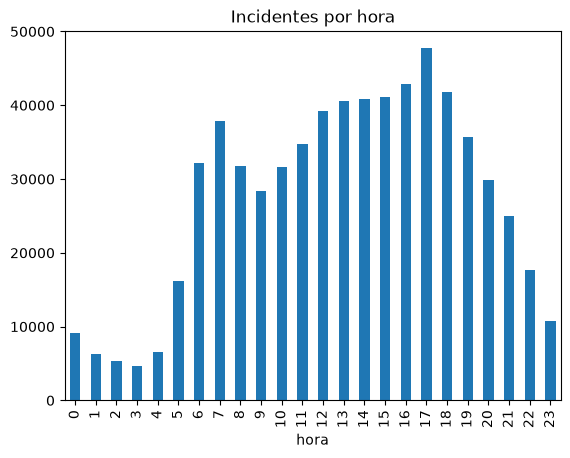

In [69]:
df["clase"].value_counts(normalize=True)
df["hora"].value_counts().sort_index().plot.bar()
plt.title("Incidentes por hora"); plt.show()

# 2. Preparacion
-  hora y día son circulares (las 23h están al lado de las 0h): se pasan a seno y coseno.
- clase es nominal: one-hot (get_dummies). Las clases raras se juntan en "Otras".
- Sin escalar, lat/lon (decimales) y los dummies (0/1) pesan distinto: StandardScaler.

In [70]:
top = df["clase"].value_counts().index[:4]
df["clase_g"] = np.where(df["clase"].isin(top), df["clase"], "Otras")
 
X = pd.DataFrame({
    "lat": df["lat"], "lon": df["lon"],
    "hora_sin": np.sin(2 * np.pi * df["hora"] / 24), "hora_cos": np.cos(2 * np.pi * df["hora"] / 24),
    "dia_sin": np.sin(2 * np.pi * df["dia_semana"] / 7), "dia_cos": np.cos(2 * np.pi * df["dia_semana"] / 7),
})
X = pd.concat([X, pd.get_dummies(df["clase_g"], prefix="clase", dtype=float)], axis=1)
 
scaler = StandardScaler()
Xs = scaler.fit_transform(X)          # en clustering se ajusta con todo el dataset
Xs.shape
 
# La silueta cuesta O(n²): con cientos de miles de filas se usa sample_size
N_SIL = 10000

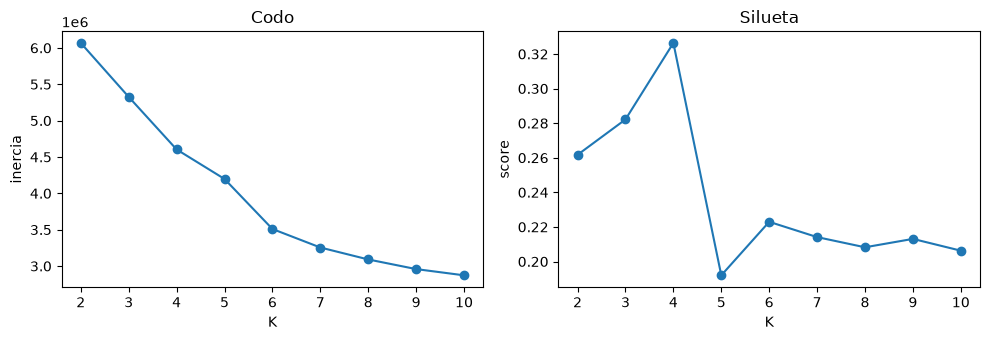

{2: np.float64(0.262), 3: np.float64(0.282), 4: np.float64(0.326), 5: np.float64(0.192), 6: np.float64(0.223), 7: np.float64(0.214), 8: np.float64(0.208), 9: np.float64(0.213), 10: np.float64(0.206)}


In [71]:
ks = range(2, 11)
inercias = [KMeans(k, n_init=10, random_state=42).fit(Xs).inertia_ for k in ks]
siluetas = [silhouette_score(Xs, KMeans(k, n_init=10, random_state=42).fit_predict(Xs),
                             sample_size=N_SIL, random_state=0) for k in ks]
 
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, inercias, "o-"); ax[0].set(title="Codo", xlabel="K", ylabel="inercia")
ax[1].plot(ks, siluetas, "o-"); ax[1].set(title="Silueta", xlabel="K", ylabel="score")
plt.tight_layout(); plt.savefig("outputs/A1_codo_silueta.png", dpi=150); plt.show()
print(dict(zip(ks, np.round(siluetas, 3))))

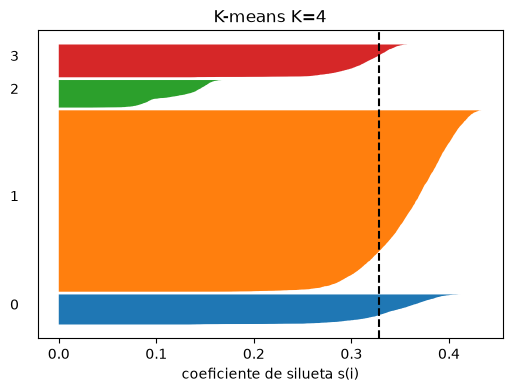

In [72]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["km"] = kmeans.fit_predict(Xs)
df["km"].value_counts().sort_index()

# Diagrama de silueta (receta del profe) sobre una muestra
idx = np.random.default_rng(0).choice(len(df), N_SIL, replace=False)
s = silhouette_samples(Xs[idx], df["km"].values[idx])
lab = df["km"].values[idx]
y0 = 0
plt.figure(figsize=(6, 4))
for c in np.unique(lab):
    s_c = np.sort(s[lab == c])
    plt.fill_betweenx(np.arange(y0, y0 + len(s_c)), 0, s_c)
    plt.text(-0.05, y0 + len(s_c) / 2, str(c))
    y0 += len(s_c) + 100
plt.axvline(s.mean(), ls="--", color="k"); plt.yticks([])
plt.xlabel("coeficiente de silueta s(i)"); plt.title(f"K-means K={K}")
plt.savefig("outputs/A2_diagrama_silueta.png", dpi=150); plt.show()

# 3. Clustering jeraquico 

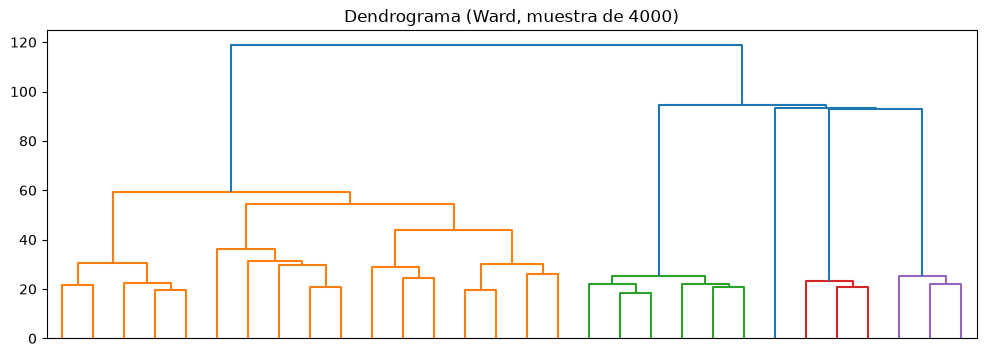

jer
1    2674
4     700
2     497
3     129
Name: count, dtype: int64

In [73]:
muestra = df.sample(4000, random_state=42)
Xm = Xs[muestra.index]
 
Z = linkage(Xm, method="ward")                       # 1. construir el árbol
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)   # 2. dibujarlo (solo los últimos 30 cortes)
plt.title("Dendrograma (Ward, muestra de 4000)")
plt.savefig("outputs/A3_dendrograma.png", dpi=150); plt.show()
 
muestra = muestra.assign(jer=fcluster(Z, t=K, criterion="maxclust"))   # 3. cortar en K grupos
muestra["jer"].value_counts()

In [74]:
for met in ["single", "complete", "average", "ward"]:
    print(met, np.bincount(fcluster(linkage(Xm, method=met), t=K, criterion="maxclust"))[1:])
 
# Jerárquico vs K-means sobre la misma muestra: tabla cruzada (las etiquetas son arbitrarias)
pd.crosstab(muestra["km"], muestra["jer"])

single [ 129  288  412 3171]
complete [  28  129 2626 1217]
average [ 129   27  283 3561]
ward [2674  497  129  700]


jer,1,2,3,4
km,,,,
0,0,0,0,412
1,2669,0,0,0
2,0,0,129,288
3,5,497,0,0


# 4. DBSCAN (haversine): puntos calientes en el mapa
Igual que el caso California de la clase:
- lat/lon NO se escalan (ya comparten unidad): métrica haversine, coordenadas en radianes,
 eps = km / 6371 para que se lea en kilómetros.
- Solo lugar: un hotspot es un sitio. La hora y la clase se miran después, en el perfil.
- Truco por tamaño: muchos incidentes ocurren en la misma esquina. Se agrupan por coordenada
redondeada (~11 m) y cada punto único pesa lo que repite (sample_weight). Es el mismo DBSCAN, solo más rápido.

In [75]:
R = 6371   # radio de la Tierra (km)
df["lat_r"] = df["lat"].round(4)
df["lon_r"] = df["lon"].round(4)
pts = df.groupby(["lat_r", "lon_r"]).size().rename("w").reset_index()
coords = np.radians(pts[["lat_r", "lon_r"]])
print(f"{len(pts):,} puntos únicos de {len(df):,} incidentes")

21,399 puntos únicos de 657,755 incidentes


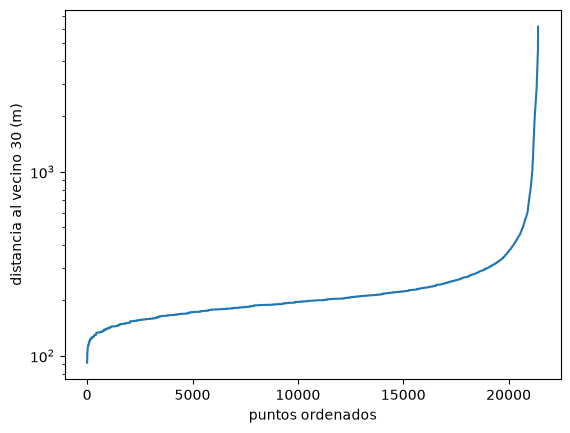

In [76]:
min_samples = 30
nn = NearestNeighbors(n_neighbors=min_samples, metric="haversine", algorithm="ball_tree").fit(coords)
dist, _ = nn.kneighbors(coords)
k_dist = np.sort(dist[:, -1]) * R * 1000
plt.plot(k_dist); plt.yscale("log")
plt.xlabel("puntos ordenados"); plt.ylabel(f"distancia al vecino {min_samples} (m)")
plt.savefig("outputs/A4_k_distancia.png", dpi=150); plt.show()

In [77]:
def correr_dbscan(eps_m, min_samples):
    db = DBSCAN(eps=(eps_m / 1000) / R, min_samples=min_samples,
                metric="haversine", algorithm="ball_tree")
    return db.fit_predict(coords, sample_weight=pts["w"])
 
filas = []
for eps_m in [100, 200, 300, 500]:
    for ms in [50, 100, 200]:
        lab = correr_dbscan(eps_m, ms)
        ruido = pts.loc[lab == -1, "w"].sum() / pts["w"].sum()
        filas.append((eps_m, ms, len(set(lab)) - (1 if -1 in lab else 0), round(ruido, 3)))
pd.DataFrame(filas, columns=["eps_m", "min_samples", "n_hotspots", "pct_ruido"])

,eps_m,min_samples,n_hotspots,pct_ruido
0,100,50,329,0.016
1,100,100,319,0.046
2,100,200,340,0.138
3,200,50,24,0.003
4,200,100,23,0.006
5,200,200,21,0.015
6,300,50,12,0.002
7,300,100,8,0.003
8,300,200,8,0.005
9,500,50,8,0.001


In [78]:
# Configuración elegida (justifícala en el informe: rodilla del k-distancia, % ruido razonable, hotspots interpretables)
EPS_M, MIN_SAMPLES = 200, 100
pts["db"] = correr_dbscan(EPS_M, MIN_SAMPLES)
df = df.merge(pts[["lat_r", "lon_r", "db"]], on=["lat_r", "lon_r"])
 
n_hot = df.loc[df["db"] != -1, "db"].nunique()
print(f"{n_hot} hotspots · {(df['db'] == -1).mean():.0%} ruido (incidentes aislados)")
 
# Silueta sin ruido, en haversine, con sample_size (como en California). Se reporta junto al % de ruido.
mask = (df["db"] != -1).to_numpy()
c_all = np.radians(df[["lat", "lon"]].to_numpy())
sil_db = silhouette_score(c_all[mask], df["db"].to_numpy()[mask], metric="haversine",
                          sample_size=N_SIL, random_state=0)
print("silueta DBSCAN (sin ruido):", round(sil_db, 3))

23 hotspots · 1% ruido (incidentes aislados)
silueta DBSCAN (sin ruido): -0.246


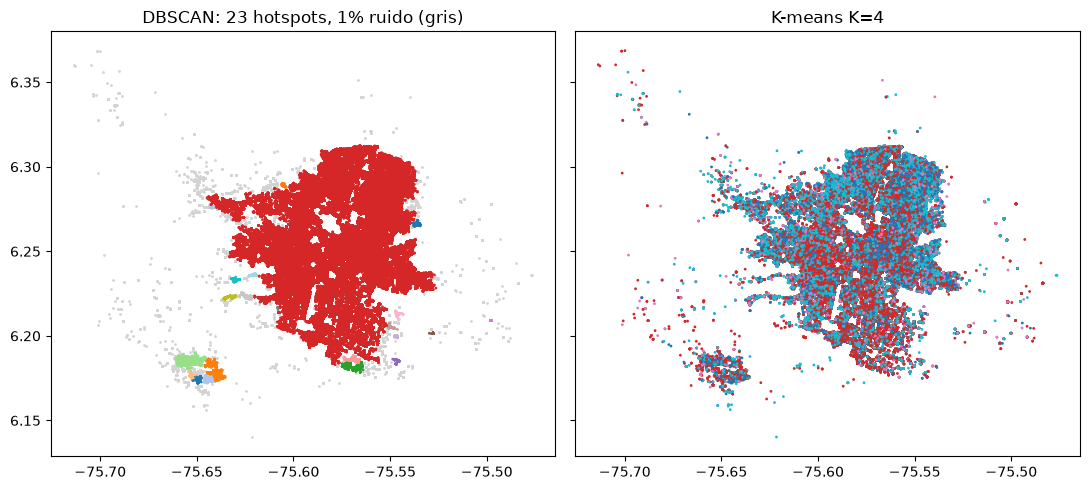

In [79]:
# Mapa: DBSCAN vs K-means
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
r = df["db"] == -1
ax[0].scatter(df.loc[r, "lon"], df.loc[r, "lat"], s=1, c="lightgray")
ax[0].scatter(df.loc[~r, "lon"], df.loc[~r, "lat"], s=1, c=df.loc[~r, "db"] % 20, cmap="tab20")
ax[0].set_title(f"DBSCAN: {n_hot} hotspots, {r.mean():.0%} ruido (gris)")
ax[1].scatter(df["lon"], df["lat"], s=1, c=df["km"], cmap="tab10")
ax[1].set_title(f"K-means K={K}")
plt.tight_layout(); plt.savefig("outputs/A5_mapas.png", dpi=150); plt.show()
 

# 5. Comparación 
la silueta NO es comparable entre métodos con geometrías distintas

In [80]:
comparacion = pd.DataFrame({
    "método": ["K-means", "Jerárquico (Ward)", "DBSCAN haversine"],
    "parámetros": [f"K={K}", f"corte K={K}", f"eps={EPS_M} m, min_samples={MIN_SAMPLES}"],
    "espacio": ["lugar+hora+día+clase"] * 2 + ["solo lugar"],
    "grupos": [K, K, n_hot],
    "% ruido": [0, 0, round((df["db"] == -1).mean() * 100, 1)],
    "silueta": [round(silhouette_score(Xs, df["km"], sample_size=N_SIL, random_state=0), 3),
                round(silhouette_score(Xm, muestra["jer"]), 3), round(sil_db, 3)],
})
comparacion

,método,parámetros,espacio,grupos,% ruido,silueta
0,K-means,K=4,lugar+hora+día+clase,4,0.0,0.326
1,Jerárquico (Ward),corte K=4,lugar+hora+día+clase,4,0.0,0.312
2,DBSCAN haversine,"eps=200 m, min_samples=100",solo lugar,23,0.6,-0.246


# 6. Interpretación

In [81]:
print(df.columns.tolist())
print(len(df), Xs.shape[0])

['LLAVE', 'AÑO', 'FECHA_INCIDENTE', 'HORA_INCIDENTE', 'clase', 'GRAVEDAD_INCIDENTE', 'DIRECCION_INTERPOLADA', 'lat', 'lon', 'Codigo Comuna Planeacion', 'comuna', 'Codigo Barrio Planeacion', 'Barrio Planeacion', 'fecha', 'hora', 'dia_semana', 'fin_de_semana', 'anio', 'con_victimas', 'clase_g', 'km', 'lat_r', 'lon_r', 'db']
657755 657755


In [82]:
dummies = pd.get_dummies(df["clase_g"], prefix="clase", dtype=float)
base = pd.concat([df[["hora", "fin_de_semana", "con_victimas"]], dummies], axis=1)
 
perfil = base.groupby(df["km"]).mean().round(2)
perfil.insert(0, "n", df["km"].value_counts().sort_index())
perfil.insert(1, "comuna_top", df.groupby("km")["comuna"].agg(lambda s: s.value_counts().index[0]))
perfil

,n,comuna_top,hora,fin_de_semana,con_victimas,clase_Atropello,clase_Caida Ocupante,clase_Choque,clase_Otras,clase_Otro
km,,,,,,,,,,
0,70187,La Candelaria,14.00,0.29,1.00,1.0,0.0,0.0,0.0,0.0
1,437818,La Candelaria,13.24,0.24,0.35,0.0,0.0,1.0,0.0,0.0
2,67903,La Candelaria,12.75,0.26,0.99,0.0,0.7,0.0,0.3,0.0
3,81847,La Candelaria,12.61,0.25,0.98,0.0,0.0,0.0,0.0,1.0


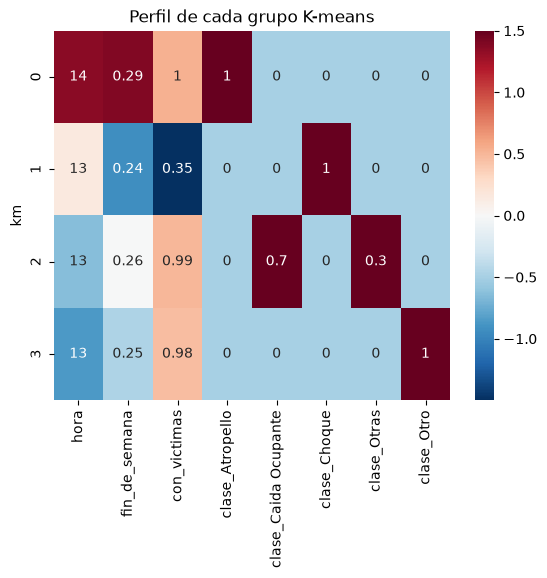

In [83]:
# Heatmap en z-score (como el de USArrests): ¿qué es alto o bajo en cada grupo respecto al promedio?
num = perfil.drop(columns=["n", "comuna_top"])
sns.heatmap((num - num.mean()) / num.std(), annot=num, cmap="RdBu_r", center=0)
plt.title("Perfil de cada grupo K-means"); plt.savefig("outputs/A6_perfiles.png", dpi=150); plt.show()

In [84]:
# Validación externa: χ² de independencia (clase de EDA) entre grupo y víctimas
tabla = pd.crosstab(df["km"], df["con_victimas"])
chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
print(f"Tasa global de víctimas: {df['con_victimas'].mean():.3f} | χ² p-valor = {p:.3g}")
print("Frecuencia esperada mínima:", esperadas.min().round(1))
print("con n tan grande casi todo sale 'significativo'; mira la DIFERENCIA en tasa, no solo el p-valor.")

Tasa global de víctimas: 0.567 | χ² p-valor = 0
Frecuencia esperada mínima: 29406.7
OJO: con n tan grande casi todo sale 'significativo'; mira la DIFERENCIA en tasa, no solo el p-valor.


In [85]:
# DBSCAN: 10 hotspots más grandes vs ruido (los incidentes aislados NO son basura: son información)
grandes = df.loc[df["db"] != -1, "db"].value_counts().head(10).index
df["zona"] = np.where(df["db"].isin(grandes), df["db"], np.where(df["db"] == -1, -1, -2))
df[df["zona"] != -2].groupby("zona").agg(
    n=("hora", "size"), hora_media=("hora", "mean"), fin_semana=("fin_de_semana", "mean"),
    clase_top=("clase_g", lambda s: s.value_counts().index[0]),
    comuna_top=("comuna", lambda s: s.value_counts().index[0]),
    tasa_victimas=("con_victimas", "mean")).round(2)

,n,hora_media,fin_semana,clase_top,comuna_top,tasa_victimas
zona,,,,,,
-1,4002,13.09,0.30,Choque,Corregimiento de Santa Elena,0.70
2,1065,13.36,0.29,Choque,Corregimiento de San Antonio de Prado,0.71
4,880,13.79,0.19,Choque,El Poblado,0.25
5,2299,13.32,0.29,Choque,Corregimiento de San Antonio de Prado,0.74
6,645810,13.19,0.25,Choque,La Candelaria,0.57
7,609,14.02,0.20,Choque,El Poblado,0.28
10,425,12.88,0.36,Caida Ocupante,Corregimiento de Santa Elena,0.85
11,201,12.66,0.22,Choque,El Poblado,0.59
15,310,13.78,0.29,Choque,Corregimiento de Altavista,0.87


In [86]:
# Cruce de métodos: patrones que persisten = estructura real
pd.crosstab(df["km"], np.where(df["db"] == -1, "aislado", "en hotspot"), normalize="index").round(2)

col_0,aislado,en hotspot
km,,
0,0.01,0.99
1,0.00,1.00
2,0.01,0.99
3,0.01,0.99


# 7. Perfilado

In [88]:
# Medianas y medias de las variables que caracterizan cada grupo
df["noche"] = ((df["hora"] >= 22) | (df["hora"] <= 5)).astype(int)
df["hora_pico"] = df["hora"].isin([6, 7, 8, 17, 18, 19]).astype(int)
resumen = df.groupby("km").agg(
    n=("hora", "size"),
    hora_mediana=("hora", "median"),
    pct_noche=("noche", "mean"),
    pct_hora_pico=("hora_pico", "mean"),
    pct_fin_semana=("fin_de_semana", "mean"),
    tasa_victimas=("con_victimas", "mean"),
).round(2)
resumen["pct_del_total"] = (resumen["n"] / len(df)).round(3)
resumen["clase_top"] = df.groupby("km")["clase_g"].agg(lambda s: s.value_counts().index[0])
resumen["comuna_top"] = df.groupby("km")["comuna"].agg(lambda s: s.value_counts().index[0])
resumen

,n,hora_mediana,pct_noche,pct_hora_pico,pct_fin_semana,tasa_victimas,pct_del_total,clase_top,comuna_top
km,,,,,,,,,
0,70187,15.0,0.11,0.34,0.29,1.00,0.107,Atropello,La Candelaria
1,437818,14.0,0.10,0.34,0.24,0.35,0.666,Choque,La Candelaria
2,67903,13.0,0.16,0.36,0.26,0.99,0.103,Caida Ocupante,La Candelaria
3,81847,13.0,0.17,0.37,0.25,0.98,0.124,Otro,La Candelaria


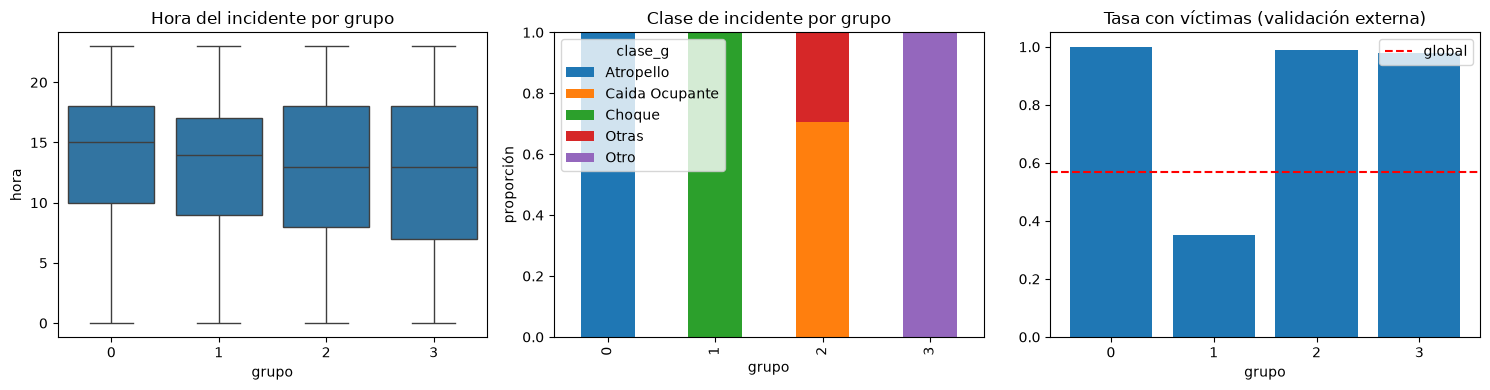

In [89]:
# Gráficos del perfil: hora por grupo, mezcla de clases y tasa de víctimas
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df.sample(50000, random_state=1), x="km", y="hora", ax=ax[0])
ax[0].set(title="Hora del incidente por grupo", xlabel="grupo")
pd.crosstab(df["km"], df["clase_g"], normalize="index").plot.bar(stacked=True, ax=ax[1])
ax[1].set(title="Clase de incidente por grupo", xlabel="grupo", ylabel="proporción")
ax[2].bar(resumen.index.astype(str), resumen["tasa_victimas"])
ax[2].axhline(df["con_victimas"].mean(), color="r", ls="--", label="global")
ax[2].set(title="Tasa con víctimas (validación externa)", xlabel="grupo"); ax[2].legend()
plt.tight_layout(); plt.savefig("outputs/A7_perfil_grupos.png", dpi=150); plt.show()
 

In [ ]:
nombres = {   # <<< ejemplos: CAMBIA por lo que de verdad salga en tu resumen
    0: ("Choque de hora pico", "Reforzar agentes de tránsito 6-9h y 17-19h en las comunas del grupo"),
    1: ("Atropellos con víctimas", "Ambulancia en despacho inmediato y campañas peatonales"),
    2: ("Incidente nocturno", "Operativos de control de alcohol y velocidad entre 22h y 5h"),
    3: ("Daño material menor", "Atención de tránsito sin ambulancia; prioridad baja"),
}
perfilado = resumen[["n", "pct_del_total", "hora_mediana", "pct_noche", "tasa_victimas", "clase_top", "comuna_top"]].copy()
perfilado["nombre"] = [nombres[k][0] for k in perfilado.index]
perfilado["accion"] = [nombres[k][1] for k in perfilado.index]
perfilado.to_csv("outputs/A8_perfilado.csv")
perfilado

In [ ]:
tabla = pd.crosstab(df["km"], df["con_victimas"])
chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
print(f"Tasa global de víctimas: {df['con_victimas'].mean():.3f} | χ² p-valor = {p:.3g}")
print("Frecuencia esperada mínima:", esperadas.min().round(1))
print("OJO: con n tan grande casi todo sale 'significativo'; mira la DIFERENCIA en tasa, no solo el p-valor.")

# 8. Puente a la Parte B: DBSCAN + KNN
DBSCAN no tiene predict(). Para asignar hotspot a incidentes NUEVOS (el test 2023-2025)
se entrena un KNN solo con los puntos núcleo del train, y lo que queda lejos de todo núcleo es "aislado" (-1).
Así el hotspot se ajusta SOLO con train y no hay fuga de datos.
 

In [87]:
train = df[df["anio"] <= 2022]
test = df[df["anio"] > 2022]
 
pt = train.groupby(["lat_r", "lon_r"]).size().rename("w").reset_index()
ct = np.radians(pt[["lat_r", "lon_r"]])
dbt = DBSCAN(eps=(EPS_M / 1000) / R, min_samples=MIN_SAMPLES, metric="haversine", algorithm="ball_tree")
lab_t = dbt.fit_predict(ct, sample_weight=pt["w"])
 
nucleos = ct.to_numpy()[dbt.core_sample_indices_]
et_nucleos = lab_t[dbt.core_sample_indices_]
knn = KNeighborsClassifier(n_neighbors=1, metric="haversine").fit(nucleos, et_nucleos)
 
def asignar_hotspot(d):
    c = np.radians(d[["lat", "lon"]].to_numpy())
    dist, _ = knn.kneighbors(c, n_neighbors=1)
    y = knn.predict(c)
    y[dist[:, 0] > (EPS_M / 1000) / R] = -1       # lejos de todo núcleo = aislado
    return y
 
if len(test):
    print("% aislados en test:", (asignar_hotspot(test) == -1).mean().round(3))
 
# %%
df[["lat", "lon", "hora", "dia_semana", "anio", "clase", "comuna", "con_victimas", "km", "db"]] \
    .to_csv("outputs/parte_A_etiquetas.csv", index=False)
 

% aislados en test: 0.016
